# 04 · Tuning the model on the validation window

So far LightGBM has run on sensible defaults that were never tested. This notebook searches its
settings, using only the **validation window** (the six months before the test year), and
decides in advance how the winner is picked:

- **Score: pinball loss**, the standard score for quantile forecasts (it rewards a p10 that's
  exceeded 90% of the time, a p90 exceeded 10% of the time, and a sharp p50). It's computed on
  every half-hour, so it's far less noisy than £, which depends on a handful of volatile days.
- **Check: £ and MAE** are shown alongside, so we'd notice if a "better" forecast earned less.

Two stages:

1. **Random search** over tree settings (12 random configurations + the current default),
   retrained every 28 days to keep runtime down.
2. **Targeted questions** on the best settings, retrained weekly as in production:
   how should the central forecast be trained (median vs mean), and should `embedded_age_h`
   stay (notebook 03 suspected it encodes data gaps)?

Runtime: ~10–15 minutes.

In [1]:
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import style

from flexcast.backtest import BacktestConfig, days_between, feature_table, run, summarise
from flexcast.features import ALL_COLUMNS
from flexcast.history import History
from flexcast.models.lgbm import LGBMQuantile
from flexcast.storage import Storage

style.use()
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
history = History.load(Storage(f"file://{ROOT / 'data'}"))
VAL_START, VAL_END, TRAIN_START = date(2025, 4, 21), date(2025, 10, 19), date(2024, 10, 20)
# The settings before this notebook (the code defaults now hold the tuned ones).
PRE_TUNING = {"num_leaves": 31, "min_data_in_leaf": 50, "feature_fraction": 0.9, "lambda_l2": 0.0}
PRE_TUNING_ROUNDS = 300

table = feature_table(history, days_between(TRAIN_START, VAL_END), pd.Timestamp("09:00").time())
print(f"feature table: {len(table[0]):,} rows × {table[0].shape[1]} columns")

feature table: 17,520 rows × 33 columns


## Why not tune on £ directly?

How much does a strategy's £ over these 182 days move just from *which days happen to be in
the window*? Resampling days from the current model's validation results:

In [2]:
cfg_fast = BacktestConfig(
    test_start=VAL_START,
    test_end=VAL_END,
    train_start=TRAIN_START,
    retrain_every_days=28,
    validation_days=0,
)
default = run(
    history,
    cfg_fast,
    {"default": lambda: LGBMQuantile(params=PRE_TUNING, num_rounds=PRE_TUNING_ROUNDS)},
    table=table,
)
d = default.daily[default.daily.strategy == "default"]
rng = np.random.default_rng(0)
gbp = [rng.choice(d.value_gbp.to_numpy(), len(d)).mean() * 365 for _ in range(2000)]
pin = [rng.choice(d.pinball.to_numpy(), len(d)).mean() for _ in range(2000)]
print(
    f"£/yr: {d.value_gbp.mean() * 365:.1f}, 90% resampling range ±{np.subtract(*np.percentile(gbp, [95, 5])) / 2:.1f} "
    f"({np.subtract(*np.percentile(gbp, [95, 5])) / 2 / abs(d.value_gbp.mean() * 365):.0%} of the value)"
)
print(
    f"pinball: {d.pinball.mean():.2f}, 90% resampling range ±{np.subtract(*np.percentile(pin, [95, 5])) / 2:.2f} "
    f"({np.subtract(*np.percentile(pin, [95, 5])) / 2 / d.pinball.mean():.0%} of the value)"
)

£/yr: 22.5, 90% resampling range ±12.8 (57% of the value)
pinball: 8.46, 90% resampling range ±0.38 (5% of the value)


£ is several times noisier relative to its size, so ranking a dozen configurations by £ would
mostly rank luck. Pinball is the selection score; £ is the sanity check.

## Stage 1: random search over tree settings

In [3]:
space = {
    "num_leaves": [15, 31, 63, 127],
    "learning_rate": [0.02, 0.05, 0.1],
    "num_rounds": [150, 300, 600],
    "min_data_in_leaf": [20, 50, 100, 200],
    "feature_fraction": [0.6, 0.8, 0.9, 1.0],
    "lambda_l2": [0.0, 1.0, 10.0],
}
pick = np.random.default_rng(42)
configs = {"default": {**PRE_TUNING, "num_rounds": PRE_TUNING_ROUNDS}}
while len(configs) < 13:
    c = {k: v[pick.integers(len(v))] for k, v in space.items()}
    configs[f"cfg{len(configs):02d}"] = c


def factory(c: dict[str, float]):  # noqa: ANN201
    params = {k: v for k, v in c.items() if k != "num_rounds"}
    return lambda: LGBMQuantile(params=params, num_rounds=int(c["num_rounds"]))


search = run(history, cfg_fast, {name: factory(c) for name, c in configs.items()}, table=table)
results = summarise(search.daily).drop(index="perfect")
results = results.join(pd.DataFrame(configs).T).sort_values("pinball")
results[["pinball", "mae", "gbp_per_year", "coverage_80", *space]].style.format(
    {"pinball": "{:.3f}", "mae": "{:.2f}", "gbp_per_year": "{:.1f}", "coverage_80": "{:.0%}"}
)

,pinball,mae,gbp_per_year,coverage_80,num_leaves,learning_rate,num_rounds,min_data_in_leaf,feature_fraction,lambda_l2
strategy,,,,,,,,,,
cfg08,8.172,27.23,28.5,73%,63.000000,0.050000,150.000000,200.000000,0.800000,10.000000
cfg10,8.233,27.18,28.2,73%,31.000000,0.020000,300.000000,20.000000,0.900000,10.000000
cfg06,8.239,27.39,28.3,80%,31.000000,0.020000,150.000000,100.000000,1.000000,0.000000
cfg05,8.311,27.43,23.0,68%,127.000000,0.050000,300.000000,200.000000,0.900000,1.000000
cfg02,8.324,27.40,23.1,70%,15.000000,0.100000,150.000000,20.000000,0.900000,10.000000
cfg11,8.446,27.69,18.9,64%,127.000000,0.100000,300.000000,200.000000,0.800000,0.000000
default,8.463,27.49,22.5,68%,31.000000,nan,300.000000,50.000000,0.900000,0.000000
cfg07,8.492,27.57,17.3,63%,127.000000,0.100000,150.000000,100.000000,0.600000,10.000000
cfg01,8.516,27.47,25.4,68%,15.000000,0.100000,300.000000,50.000000,0.800000,10.000000


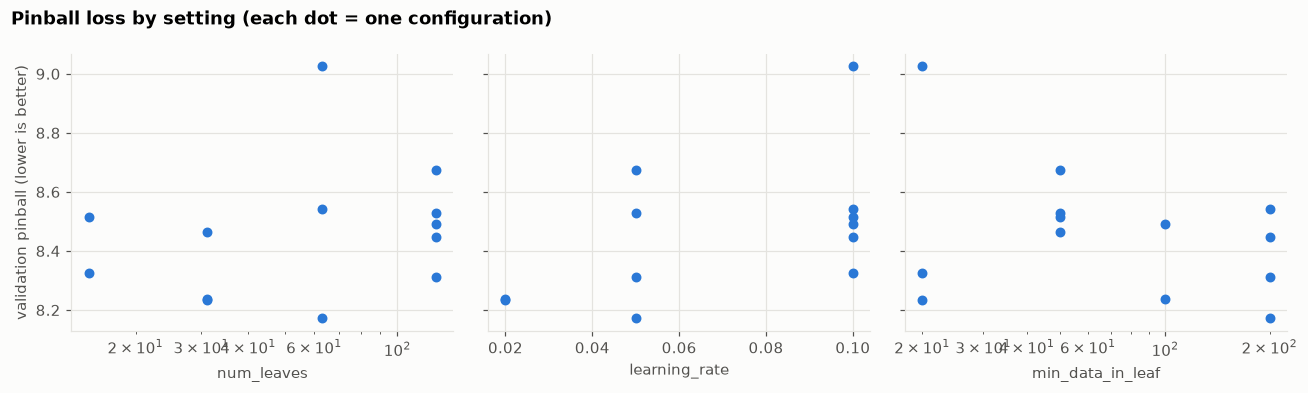

rank correlation between pinball and £ across configurations: -0.78 (negative = better forecasts earn more)


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
for ax, key in zip(axes, ("num_leaves", "learning_rate", "min_data_in_leaf"), strict=True):
    ax.scatter(results[key].astype(float), results["pinball"], color=style.BLUE, s=30)
    ax.set(xlabel=key, xscale="log" if key != "learning_rate" else "linear")
axes[0].set(ylabel="validation pinball (lower is better)")
fig.suptitle(
    "Pinball loss by setting (each dot = one configuration)", x=0.01, ha="left", fontweight="bold"
)
plt.tight_layout()
plt.show()

corr = results[["pinball", "gbp_per_year"]].corr(method="spearman").iloc[0, 1]
print(
    f"rank correlation between pinball and £ across configurations: {corr:+.2f} "
    "(negative = better forecasts earn more)"
)

## Stage 2: targeted questions on the best settings, weekly retraining

In [5]:
best_name = results.index[0]
best = configs[best_name]
best_params = {k: v for k, v in best.items() if k != "num_rounds"}
print(f"best stage-1 configuration: {best_name} {best}")
no_age = [c for c in ALL_COLUMNS if c != "embedded_age_h"]

cfg_weekly = BacktestConfig(
    test_start=VAL_START, test_end=VAL_END, train_start=TRAIN_START, validation_days=0
)
variants = {
    "default settings": lambda: LGBMQuantile(params=PRE_TUNING, num_rounds=PRE_TUNING_ROUNDS),
    "tuned · p50 median": lambda: LGBMQuantile(
        params=best_params, num_rounds=int(best["num_rounds"])
    ),
    "tuned · p50 huber": lambda: LGBMQuantile(
        params=best_params, num_rounds=int(best["num_rounds"]), p50_objective="huber"
    ),
    "tuned · p50 mean": lambda: LGBMQuantile(
        params=best_params, num_rounds=int(best["num_rounds"]), p50_objective="regression"
    ),
    "tuned · median · no age": lambda: LGBMQuantile(
        params=best_params, num_rounds=int(best["num_rounds"]), features=no_age
    ),
}
stage2 = run(history, cfg_weekly, variants, table=table)
s2 = summarise(stage2.daily).drop(index="perfect").sort_values("pinball")
s2.style.format(
    {
        "pinball": "{:.3f}",
        "mae": "{:.2f}",
        "gbp_per_year": "{:.1f}",
        "pct_of_perfect": "{:.1f}",
        "coverage_80": "{:.0%}",
        "days": "{:.0f}",
    }
)

best stage-1 configuration: cfg08 {'num_leaves': 63, 'learning_rate': 0.05, 'num_rounds': 150, 'min_data_in_leaf': 200, 'feature_fraction': 0.8, 'lambda_l2': 10.0}


,days,gbp_per_year,pct_of_perfect,mae,pinball,coverage_80
strategy,,,,,,
tuned · p50 median,182,32.4,13.6,27.05,8.123,72%
tuned · p50 mean,182,26.9,11.3,27.33,8.170,72%
tuned · median · no age,182,28.0,11.7,27.16,8.173,71%
default settings,182,28.5,11.9,27.37,8.368,67%
tuned · p50 huber,182,0.0,0.0,33.28,9.161,72%


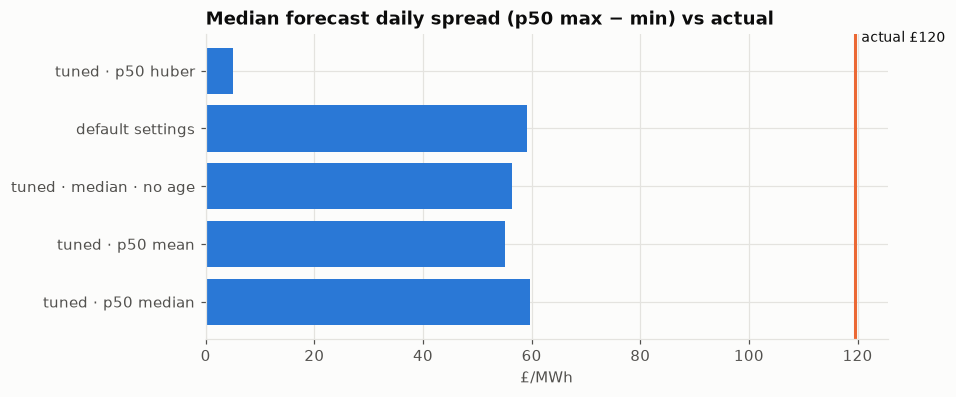

In [6]:
spread = lambda s: s.max() - s.min()  # noqa: E731
sp = (
    stage2.forecasts.groupby(["strategy", "target_date"])["p50"]
    .agg(spread)
    .groupby("strategy")
    .median()
)
actual_spread = (
    stage2.forecasts[stage2.forecasts.strategy == "perfect"]
    .groupby("target_date")["actual"]
    .agg(spread)
    .median()
)
fig, ax = plt.subplots(figsize=(8, 3.6))
order = s2.index.tolist()
ax.barh(order, sp[order], color=style.BLUE)
ax.axvline(actual_spread, color=style.ORANGE, linewidth=2)
ax.annotate(
    f"actual £{actual_spread:.0f}",
    (actual_spread, len(order) - 0.5),
    xytext=(4, 0),
    textcoords="offset points",
    color=style.TEXT,
    fontsize=9,
)
ax.set(title="Median forecast daily spread (p50 max − min) vs actual", xlabel="£/MWh")
plt.show()

## Decision

Rule, set before running: pick the lowest validation pinball; adopt a p50 objective other than
the median, or drop `embedded_age_h`, only if it also lowers pinball **and** doesn't lose £.

In [7]:
chosen = s2.index[0]
print(f"lowest validation pinball: {chosen}")
print(f"settings: {best}")
print(s2.loc[chosen, ["pinball", "mae", "gbp_per_year", "coverage_80"]].round(3).to_dict())

lowest validation pinball: tuned · p50 median
settings: {'num_leaves': 63, 'learning_rate': 0.05, 'num_rounds': 150, 'min_data_in_leaf': 200, 'feature_fraction': 0.8, 'lambda_l2': 10.0}
{'pinball': 8.123, 'mae': 27.051, 'gbp_per_year': 32.413, 'coverage_80': 0.72}


### Reading the result

- **Adopted: the tuned settings with a median p50**, which are now the code defaults. Validation
  pinball 8.37 → 8.12, MAE 27.4 → 27.1, £ 28.5 → 32.4/yr, coverage 67% → 72%.
- **Regularisation won.** The best settings make each tree leaf average at least 200 half-hours
  and penalise large leaf values: on a target this noisy, a model that's prevented from chasing
  noise generalises better.
- **Better forecasts did earn more:** across configurations, pinball and £ ranked similarly.
- **The daily spread barely changed** (~£60 vs £120 actual) for every variant, including the
  mean-trained p50. Tuning improved *timing* (which half-hours are cheap or dear), not the
  flattening.
- **Huber failed** because its default threshold (1.0) suits targets near 1, not prices near £100;
  it would need its own tuning. **Dropping `embedded_age_h` made things worse**, so it stays.